# 00 — Dataoppslag: Norsk Ordbank, korpusfrekvenser og n-gram

Startpunkt for å hente data fra prosjektets kilder. Notebooken importerer de viktigste funksjonene fra `sqlite/` og viser ett eksempel på hver:

| Seksjon | Funksjon | Kilde | Nett? |
|---|---|---|---|
| 1 | `lookup_wordform` | `lemma_former` | nei |
| 2 | `get_paradigm`, `get_verb_profile_forms`, `get_noun_profile_forms` | `lemma_former` + `ordform_flertydighet` | nei |
| 3 | `find_anchor_forms` | `ordform_flertydighet` | nei |
| 4 | `frekvens` (hjelper her) | `nb_totals` | nei |
| 5 | `sql` (fri SQL → DataFrame) | hele `ordbank.db` | nei |
| 6 | `estimate_wordform_shares` | `lemma_former` + `nb_totals` | nei |
| 7 | `build_paradigm_graph`, `inspect_component` | `lemma_former` | nei |
| 8 | `fetch_ngram_dhlab`, `fetch_ngram_sp`, `compute_paradigm_profile` | api.nb.no (cache i `ngram_cache.db`) | **ja** |

**Husk (fra `AGENTS.md`):** tell alltid fra `lemma_former`, ikke rå `fullformsliste` — den har duplikater på tvers av alternative paradigmer.

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Sørg for at prosjektroten ligger i sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sqlite.queries import (
    get_conn,
    lookup_wordform,
    get_paradigm,
    get_verb_profile_forms,
    get_noun_profile_forms,
    find_anchor_forms,
    VERB_TENSE_SLOTS,
    VERB_CORE_SLOTS,
    NOUN_CORE_SLOTS,
)
from sqlite.decomposer import estimate_wordform_shares
from sqlite.paradigm_graph import build_paradigm_graph, inspect_component
from sqlite.ngram import (
    fetch_ngram_dhlab,
    fetch_ngram_sp,
    compute_paradigm_profile,
)

pd.set_option("display.max_colwidth", 120)
conn = get_conn()  # gjenbrukes i cellene under

## 1. Slå opp en ordform
`lookup_wordform` gir alle normerte analyser av en overflateform: hvilke lemmaer (`lemma_id`) og bøyningskategorier (`boy_nummer`/`boy_tekst`) den kan tilhøre.

In [15]:
pd.DataFrame(lookup_wordform("overvåker", conn=conn))

,lemma_id,grunnform,pos,ordklasser,boy_gruppe,boy_nummer,boy_tekst,ordbok_tekst,oppslag
0,50759,overvåker,subst,subst mask appell,substantiv,1,ent ub,entall_ubestemt,overvåker
1,50758,overvåke,verb,verb,"verb, normal",2,pres,presens,overvåker


## 2. Hent et paradigme
`get_paradigm` henter alle former for et lemma, med flertydighetsstatus per form (`antall_lemma_id`, `antall_analyser`).
Oppgi `lemma_id` når grunnformen er homograf (f.eks. *bok* = boka/bøker vs. treet bøk) — ellers får du alle lemmaene med den grunnformen.

In [18]:
pd.DataFrame(get_paradigm(grunnform="overvåker", pos='verb', conn=conn))

""


Snarveier for kjernecellene: verb (`VERB_TENSE_SLOTS` = inf/pres/pret, `VERB_CORE_SLOTS` = + perf-part) og substantiv (`NOUN_CORE_SLOTS` = ent/fl × ub/be).

In [4]:
pd.DataFrame(get_verb_profile_forms(grunnform="gå", slots=VERB_CORE_SLOTS, conn=conn))[
    ["lemma_id", "boy_tekst", "oppslag", "antall_lemma_id", "alle_analyser_for_ordform"]
]

,lemma_id,boy_tekst,oppslag,antall_lemma_id,alle_analyser_for_ordform
0,25369,inf,gå,1,"gå (verb inf, id=25369) | gå (verb imp, id=25369)"
1,25369,pres,går,3,"gå (verb pres, id=25369) | går (subst , id=25380) | gåre (verb imp, id=25431)"
2,25369,pret,gikk,1,"gå (verb pret, id=25369)"
3,25369,perf-part,gått,1,"gå (verb perf-part, id=25369) | gå (verb adj <perf-part> nøyt ub ent, id=25369) | gå (verb adj <perf-part> m/f ub en..."


In [23]:
pd.DataFrame(get_noun_profile_forms(grunnform="eple", conn=conn))[
    ["lemma_id", "boy_tekst", "oppslag", "antall_lemma_id", "alle_analyser_for_ordform"]
]

,lemma_id,boy_tekst,oppslag,antall_lemma_id,alle_analyser_for_ordform
0,15075,ent ub,eple,1,"eple (subst ent ub, id=15075)"
1,15075,ent be,eplet,1,"eple (subst ent be, id=15075)"
2,15075,fl ub,epler,1,"eple (subst fl ub, id=15075)"
3,15075,fl be,epla,1,"eple (subst fl be, id=15075)"
4,15075,fl be,eplene,1,"eple (subst fl be, id=15075)"


## 3. Entydige holdepunkter i et paradigme
`find_anchor_forms` deler formene til ett lemma i `helt_entydige`, `leksem_entydige` og `flertydige_mellom_lemma`.

In [24]:
anchors = find_anchor_forms(25369, conn=conn)  # subst. «en fisker»
{kategori: [r["oppslag"] for r in rader] for kategori, rader in anchors.items()}

{'helt_entydige': ['gikk'],
 'leksem_entydige': ['gå', 'gått', 'gått', 'gått', 'gåtte', 'gåtte', 'gå'],
 'flertydige_mellom_lemma': ['går', 'gås', 'gående']}

## 4. Korpusfrekvenser (`nb_totals`)
Tabellen `nb_totals` har totalfrekvensen i hele NB-korpuset for de 500 000 vanligste ordformene (ned til frekvens 4 625). Ordformer som ikke er med, får `0` her.

In [7]:
def frekvens(ordformer: list[str]) -> pd.Series:
    """Totalfrekvens i nb_totals for en liste ordformer (0 hvis formen ikke er blant de 500 000 vanligste)."""
    plassholdere = ",".join("?" for _ in ordformer)
    rader = conn.execute(
        f"SELECT oppslag, freq FROM nb_totals WHERE oppslag IN ({plassholdere})", ordformer
    ).fetchall()
    funnet = {r["oppslag"]: r["freq"] for r in rader}
    return pd.Series({o: funnet.get(o, 0) for o in ordformer}, name="freq")


frekvens(["fisker", "fiskeren", "fiskere", "fiskerne", "fisken", "fiskene", "fiskes"])

fisker      1435424
fiskeren     215276
fiskere     1644273
fiskerne    1374105
fisken      2041508
fiskene      181593
fiskes       155338
Name: freq, dtype: int64

## 5. Fri SQL
For alt som ikke dekkes av funksjonene over. Eksempel: koble et paradigme direkte mot `nb_totals`.

In [8]:
def sql(query: str, params: tuple = ()) -> pd.DataFrame:
    """Kjør en SQL-spørring mot ordbank.db og returner resultatet som DataFrame."""
    return pd.read_sql_query(query, conn, params=params)


sql(
    """
    SELECT lf.lemma_id, lf.grunnform, lf.boy_tekst, lf.oppslag, COALESCE(t.freq, 0) AS freq
    FROM lemma_former lf
    LEFT JOIN nb_totals t ON t.oppslag = lf.oppslag
    WHERE lf.grunnform = ? AND lf.pos = 'verb' AND lf.boy_gruppe = 'verb, normal'
    ORDER BY lf.boy_nummer
    """,
    ("vite",),
)

,lemma_id,grunnform,boy_tekst,oppslag,freq
0,79435,vite,inf,vite,10407165
1,79435,vite,pres,veit,3278736
2,79435,vite,pres,vet,28819548
3,79435,vite,inf pres pass,vites,314502
4,79435,vite,pret,visste,10379153
5,79435,vite,perf-part,visst,5931339
6,79435,vite,adj <perf-part> nøyt ub ent,visst,5931339
7,79435,vite,adj <perf-part> m/f ub ent,visst,5931339
8,79435,vite,adj <perf-part> be ent,visste,10379153
9,79435,vite,adj <perf-part> fl,visste,10379153


Oversikt over tabellene og viewene i databasen:

In [9]:
sql("SELECT type, name FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

,type,name
0,table,boying
1,table,boying_grupper
2,table,fullformsliste
3,table,leddanalyse
4,table,lemma
5,table,lemma_former
6,table,lemma_paradigme
7,table,nb_totals
8,table,ordform_flertydighet
9,table,paradigme


## 6. Dekomponering av en flertydig ordform
`estimate_wordform_shares` fordeler totalfrekvensen til en flertydig form på kandidatlemmaene ut fra de entydige formene i hvert paradigme.

In [10]:
res = estimate_wordform_shares("fisker", conn=conn)
print(f"{res['oppslag']}: observert {res['obs_freq']:,}, sum estimater {res['total_raw_est']:,.0f}")
pd.DataFrame(res["candidates"])

fisker: observert 1,435,424, sum estimater 1,873,345


,lemma_id,grunnform,pos,boy_tekst,raw_est,uncapped_est,anchor_explanation,paradigm_rest,share,norm_est
0,17348,fisker,subst,ent ub,847027.760,847027.760,"0.85*ent_be(215,276) + 0.22*fl(3,018,378)","ent be: fiskeren (215,276*), fl ub: fiskere (1,644,273*), fl be: fiskerne (1,374,105*)",0.452147,649023.084353
1,17301,fisk,subst,fl ub,606520.620,606520.620,"3.34*fl_be(181,593)","ent ub: fisk (5,780,801), ent be: fisken (2,041,508*), fl be: fiskene (181,593)",0.323763,464737.877677
2,17307,fiske,verb,pres,405432.180,405432.180,"fra entydig s-passiv (155,338)","inf: fiske (3,738,310), inf pres pass: fiskes (155,338*), pret: fiska (162,459)/fisket (2,844,726), perf-part: fiska...",0.216422,310656.694368
3,17310,fiske,subst,fl ub,14364.171,14364.171,"3.34*fl_be(86,013)","ent ub: fiske (3,738,310), ent be: fisket (2,844,726), fl be: fiska (162,459)/fiskene (181,593)",0.007668,11006.343602


## 7. Paradigme-grafen
Noder er lemmaer, kanter kobler lemmaer som deler minst én ordform. `build_paradigm_graph` leser hele `lemma_former` og tar noen sekunder; bygg den én gang og gjenbruk den.

In [11]:
graph = build_paradigm_graph()
komp = inspect_component(graph, 17348)  # komponenten rundt «fisker»
print("Maks hopp:", komp["max_hop"])
display(pd.DataFrame(komp["nodes"]))
pd.DataFrame(komp["edges"])

Maks hopp: 1


,lemma_id,label,hop_dist,unambiguous_forms,shared_forms
0,17348,"fisker (subst, id=17348)",0,"[fiskere, fiskeren, fiskerne]",[fisker]
1,17301,"fisk (subst, id=17301)",1,[fisken],"[fisk, fiskene, fisker]"
2,17307,"fiske (verb, id=17307)",1,"[fiskede, fiskende, fiskes, fiskete]","[fisk, fiska, fiske, fisker, fisket]"
3,17310,"fiske (subst, id=17310)",1,[],"[fiska, fiske, fiskene, fisker, fisket]"


,u,v,n,shared_forms
0,"fisker (subst, id=17348)","fisk (subst, id=17301)",1,[fisker]
1,"fisker (subst, id=17348)","fiske (verb, id=17307)",1,[fisker]
2,"fisker (subst, id=17348)","fiske (subst, id=17310)",1,[fisker]
3,"fisk (subst, id=17301)","fiske (verb, id=17307)",2,"[fisk, fisker]"
4,"fisk (subst, id=17301)","fiske (subst, id=17310)",2,"[fiskene, fisker]"
5,"fiske (verb, id=17307)","fiske (subst, id=17310)",4,"[fiska, fiske, fisker, fisket]"


## 8. N-gram fra Nasjonalbiblioteket (krever nett)
Tidsserier hentes fra api.nb.no og mellomlagres i `sqlite/ngram_cache.db`, så gjentatte kall er raske og virker uten nett.

- `fetch_ngram_dhlab(words, period, corpus="book" | "newspapers")` → absolutte treff per år
- `fetch_ngram_sp(words, period, corpus="bok" | "avis", freq_mode="rel")` → støtter også bigram/trigram
- `compute_paradigm_profile(grunnform, pos, period)` → bøyningsprofil og stabilitetsmål for hele paradigmet

In [12]:
serier = fetch_ngram_dhlab(["gå", "går", "gikk"], period=(1950, 2020), corpus="book")
df_ngram = pd.DataFrame(serier).sort_index()
df_ngram.tail()

,gå,går,gikk
2016,145876.0,172321.0,223399.0
2017,165534.0,178818.0,256929.0
2018,153595.0,175526.0,238448.0
2019,139973.0,161708.0,209369.0
2020,112531.0,129643.0,176169.0


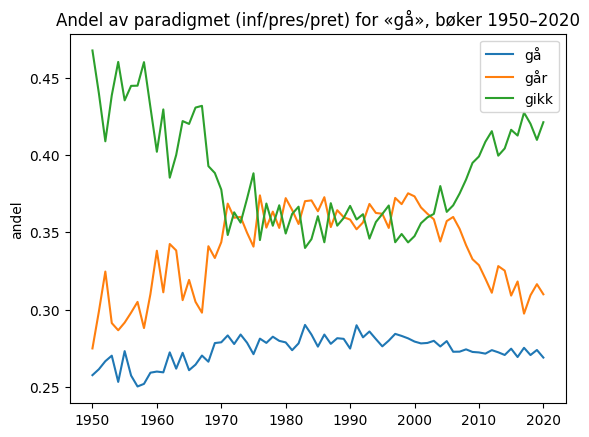

In [13]:
df_ngram.div(df_ngram.sum(axis=1), axis=0).plot(
    title="Andel av paradigmet (inf/pres/pret) for «gå», bøker 1950–2020", ylabel="andel"
);

In [14]:
profil = compute_paradigm_profile(grunnform="gå", pos="verb", period=(1950, 2020))
print(f"Dominerende: {profil['dominant_slot']} ({profil['dominant_share']:.1%}), på topp i {profil['top_slot_consistency']:.0%} av årene")
pd.DataFrame(profil["decade_profiles"]).T

Dominerende: pret (38.2%), på topp i 70% av årene


,inf,pres,pret
1950-tallet,0.260067,0.296098,0.443835
1960-tallet,0.266930,0.323496,0.409574
1970-tallet,0.279528,0.356553,0.363919
1980-tallet,0.280513,0.364285,0.355202
1990-tallet,0.281851,0.363175,0.354974
2000-tallet,0.276274,0.354292,0.369434
2010-tallet,0.272488,0.316134,0.411378
2020-tallet,0.268992,0.309896,0.421111
